# 03 · Экономические кризисы: модель Банка Англии и постсоветские страны

Недели 3–4 дорожной карты. Что здесь:

1. **Повторение модели Банка Англии** (Bluwstein, Buckmann, Joseph, Kapadia, Şimşek, 2020/2023) на их данных (JST R3) и на свежих (JST R6). Результаты считает `uv run python -m seldon.econ_boe`, тут — картинки.
2. **Постсоветские страны**: панель из Global Macro Database + Всемирного банка, целевая «девальвация ≥ 25%», что модели давали за год до 1998 / 2008–09 / 2014–15. Считает `uv run python -m seldon.econ_panel`.

AUC (area under ROC curve) — доля пар «кризис / не кризис», которые модель упорядочила правильно: 0,5 — монетка, 1 — идеал.

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from seldon import DATA_PROCESSED, PROJECT_ROOT
from seldon.countries import ISO3_TO_SHORT
R = PROJECT_ROOT / "reports"
plt.rcParams["figure.dpi"] = 110

## 1. Модель Банка Англии на JST

Их рецепт: 12 признаков (наклон кривой доходности, 2-летние изменения кредит/ВВП, деньги/ВВП, госдолг/ВВП, инвестиций/ВВП, СТО/ВВП, обслуживания долга, рост цен, акций, потребления, и «мировые» кредит и наклон), целевая — «1» за два года до системного финансового кризиса. Наша сборка совпала с их таблицей строка в строку (1249 строк, 95 кризисных).

In [2]:
cv = pd.read_csv(R / "boe_cv_results.csv")
summ = cv.groupby(["dataset", "model"]).auc.agg(["mean", "std"]).round(3)
summ["статья (R3)"] = [0.816 if m == "logreg" else 0.868 for _, m in summ.index]
summ

mean    std  статья (R3)
dataset model                            
r3      extree  0.863  0.011        0.868
        logreg  0.815  0.008        0.816
r6      extree  0.855  0.011        0.868
        logreg  0.818  0.007        0.816

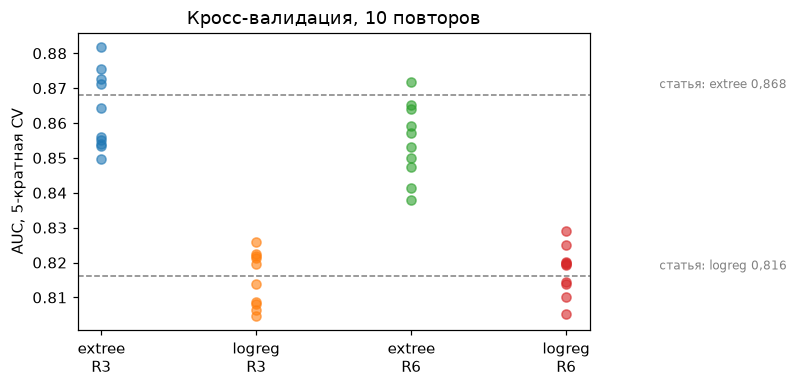

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for (ds, m), g in cv.groupby(["dataset", "model"]):
    ax.scatter([f"{m}\n{ds.upper()}"] * len(g), g.auc, alpha=.6)
ax.axhline(0.816, ls="--", c="grey", lw=1); ax.axhline(0.868, ls="--", c="grey", lw=1)
ax.text(3.6, 0.818, "статья: logreg 0,816", fontsize=8, color="grey"); ax.text(3.6, 0.870, "статья: extree 0,868", fontsize=8, color="grey")
ax.set_ylabel("AUC, 5-кратная CV"); ax.set_title("Кросс-валидация, 10 повторов"); plt.show()

### Прогноз вслепую

Их схема: учимся на годах ≤ T, предсказываем **все** последующие годы (кривая по T). Наша: предсказываем только год T+1 и склеиваем — одно число.

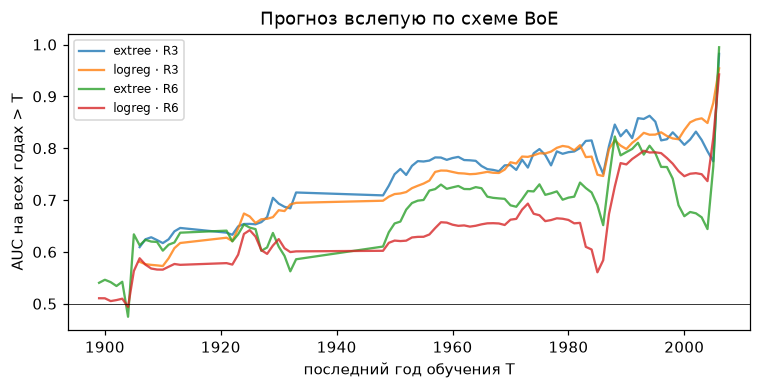

,model,scheme,n,crises,auc,brier,dataset
0,extree,next_year_pooled,1078,69,0.808,0.051,r3
1,logreg,next_year_pooled,1078,69,0.783,0.055,r3
2,extree,all_future_mean_over_T,611,40,0.757,NaN,r3
3,logreg,all_future_mean_over_T,611,40,0.745,NaN,r3
4,extree,next_year_pooled,1116,76,0.810,0.052,r6
5,logreg,next_year_pooled,1116,76,0.767,0.059,r6
6,extree,all_future_mean_over_T,622,40,0.682,NaN,r6
7,logreg,all_future_mean_over_T,622,40,0.651,NaN,r6


In [4]:
by = pd.read_csv(R / "boe_forecast_by_year.csv")
fs = pd.read_csv(R / "boe_forecast_summary.csv")
fig, ax = plt.subplots(figsize=(8, 3.5))
for (ds, m), g in by.groupby(["dataset", "model"]):
    ax.plot(g.train_end, g.auc_all_future, label=f"{m} · {ds.upper()}", lw=1.5, alpha=.8)
ax.axhline(0.5, c="k", lw=.5); ax.set_xlabel("последний год обучения T"); ax.set_ylabel("AUC на всех годах > T")
ax.legend(fontsize=8); ax.set_title("Прогноз вслепую по схеме BoE"); plt.show()
fs.round(3)

### Коэффициенты логрегрессии (R6, последний год обучения)

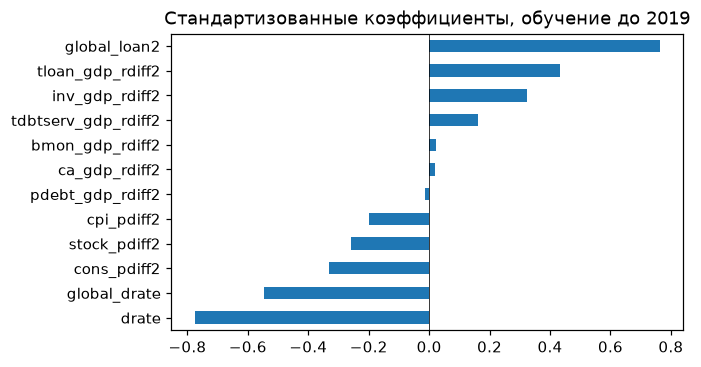

In [5]:
coef = pd.read_csv(R / "boe_coefficients.csv", index_col=0)
last = coef.iloc[-1].sort_values()
fig, ax = plt.subplots(figsize=(6, 3.5)); last.plot.barh(ax=ax); ax.axvline(0, c="k", lw=.5)
ax.set_title(f"Стандартизованные коэффициенты, обучение до {coef.index[-1]}"); plt.show()

## 2. Постсоветские страны

Признаки из GMD + ВБ в духе BoE: рост цен, рост реального потребления на душу, изменения госдолг/ВВП, инвестиций/ВВП, СТО/ВВП, кредит/ВВП, мировой кредит. Нет наклона кривой доходности, акций и обслуживания долга. Целевая `deval25` — курс к доллару (среднегодовой) вырос ≥ 25% за год после ≥ 2 спокойных лет; `gmd_crisis` — валютный или банковский кризис по хронике GMD (до 2017).

In [6]:
cov = pd.read_csv(R / "econ_post_soviet_coverage.csv"); cov

,country,iso3,nGDP,rGDP,CPI,USDfx,CA_GDP,govdebt_GDP,inv_GDP,cons,M3,credit_gdp
0,Армения,ARM,1990–2024,1990–2024,1992–2024,1990–2024,1992–2024,1993–2024,1990–2024,1990–2024,2001–2024,1992–2024
1,Азербайджан,AZE,1987–2024,1987–2024,1990–2024,1990–2024,1991–2024,1993–2024,1990–2024,1990–2024,2000–2024,1992–2024
2,Беларусь,BLR,1987–2024,1987–2024,1987–2024,1990–2024,1992–2024,1992–2024,1987–2024,1987–2024,2001–2021,1994–2021
3,Эстония,EST,1980–2024,1980–2024,1990–2024,1990–2024,1992–2024,1995–2024,1987–2024,1987–2024,—,2004–2024
4,Грузия,GEO,1960–2024,1960–2024,1991–2024,1990–2024,1993–2024,1995–2024,1980–2024,1980–2024,2000–2024,1995–2024
5,Казахстан,KAZ,1987–2024,1987–2024,1991–2024,1990–2024,1992–2024,1993–2024,1987–2024,1987–2024,2000–2024,1993–2024
6,Кыргызстан,KGZ,1987–2024,1987–2024,1991–2024,1990–2024,1992–2024,1994–2024,1987–2024,1987–2024,2001–2022,1995–2024
7,Литва,LTU,1987–2024,1987–2024,1987–2024,1990–2024,1993–2024,1994–2024,1987–2024,1987–2024,—,2010–2024
8,Латвия,LVA,1965–2024,1965–2024,1990–2024,1990–2024,1992–2024,1994–2024,1980–2024,1980–2024,—,2010–2024
9,Молдова,MDA,1990–2024,1990–2024,1991–2024,1990–2024,1992–2024,1995–2024,1990–2024,1990–2024,2001–2024,1991–2024


In [7]:
crises = pd.read_csv(R / "econ_crises_post_soviet.csv")
crises[crises.year >= 1996].round(2)

,iso3,year,deval,deval25,CurrencyCrisis,BankingCrisis,country
2,AZE,2015,0.31,1,1.0,1.0,Азербайджан
4,BLR,1997,0.97,0,1.0,0.0,Беларусь
5,BLR,2009,0.31,1,1.0,0.0,Беларусь
6,BLR,2015,0.56,1,1.0,0.0,Беларусь
9,GEO,1999,0.46,1,1.0,0.0,Грузия
10,GEO,2015,0.29,1,0.0,0.0,Грузия
11,KAZ,1999,0.53,1,1.0,0.0,Казахстан
12,KAZ,2008,-0.02,0,0.0,1.0,Казахстан
13,KAZ,2014,0.18,0,0.0,1.0,Казахстан
14,KAZ,2015,0.23,0,1.0,0.0,Казахстан


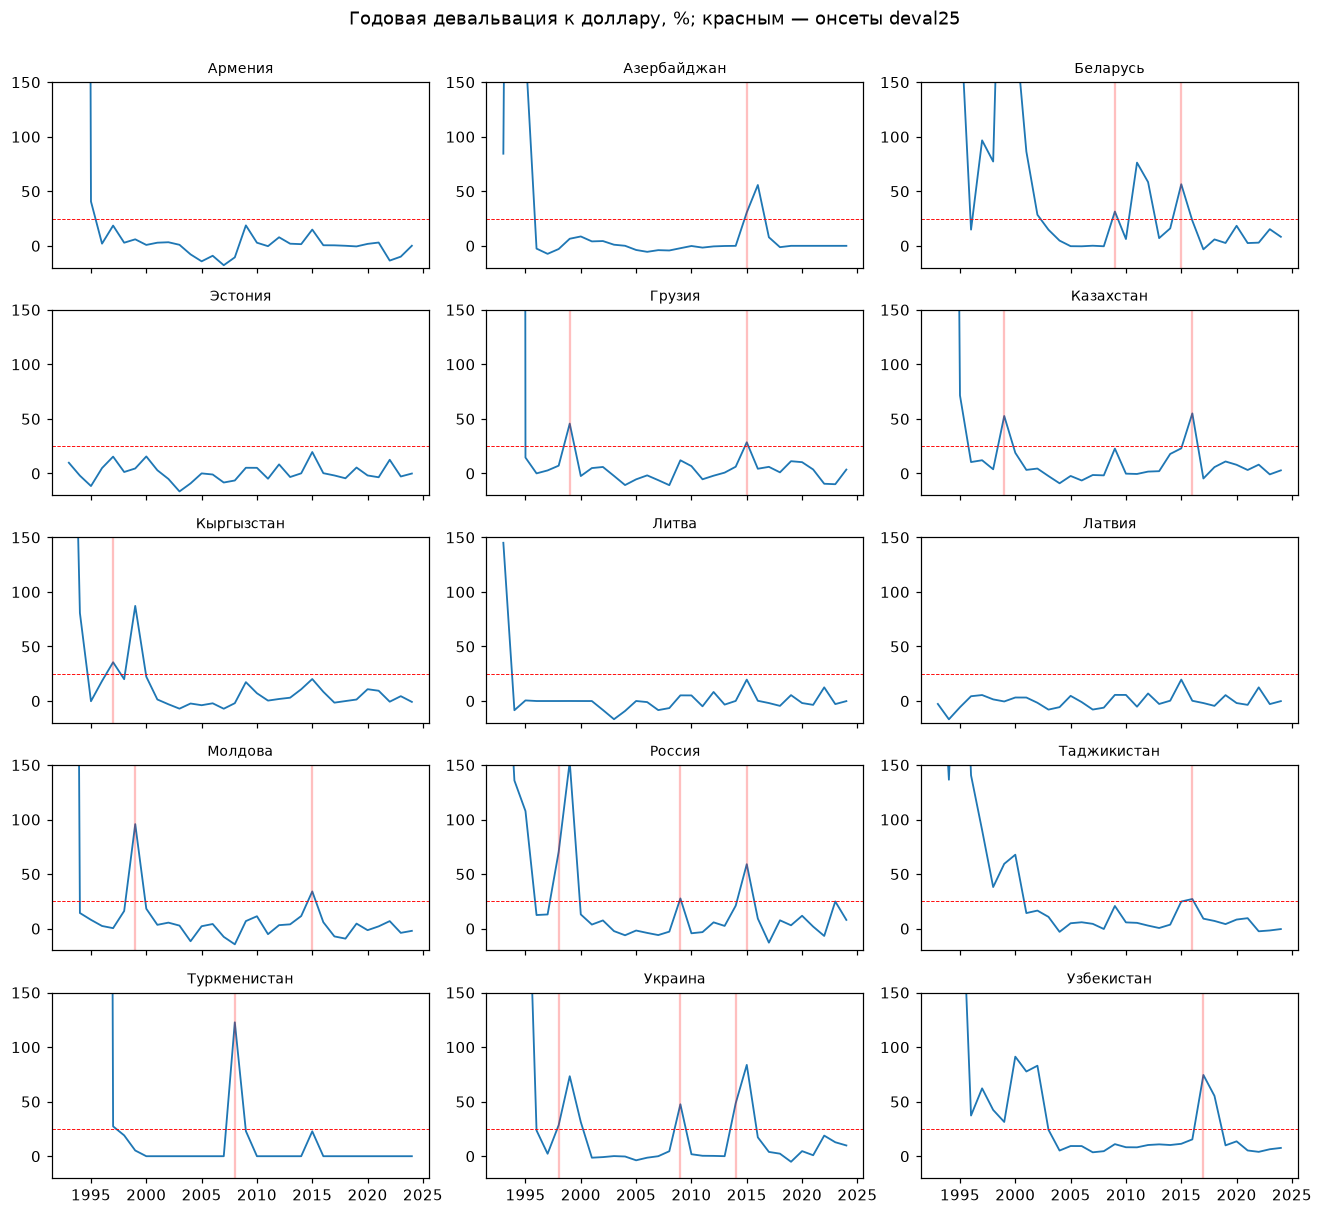

In [8]:
pan = pd.read_parquet(DATA_PROCESSED / "econ_panel.parquet")
ps = pan[pan.post_soviet & (pan.year >= 1993)]
fig, axes = plt.subplots(5, 3, figsize=(12, 11), sharex=True)
for ax, (iso, g) in zip(axes.flat, ps.groupby("iso3")):
    ax.plot(g.year, 100 * g.deval, lw=1.2); ax.axhline(25, c="r", lw=.6, ls="--")
    for y in g.loc[g.deval25 == 1, "year"]: ax.axvline(y, c="r", alpha=.25)
    ax.set_title(ISO3_TO_SHORT[iso], fontsize=9); ax.set_ylim(-20, 150)
fig.suptitle("Годовая девальвация к доллару, %; красным — онсеты deval25", y=1.0); plt.tight_layout(); plt.show()

### Метрики вслепую (с 1996)

`jst_transfer` — логрегрессия BoE, обученная на JST, применённая без переобучения; `own_*` — наши модели на панели GMD по всем странам; `kr_*` — те же плюс признаки из литературы о валютных кризисах (инфляция, СТО, резервы, реальный курс, прошлая девальвация). `auc_within_year` — среднее AUC по годам: умеет ли модель ранжировать страны внутри года.

In [9]:
met = pd.read_csv(R / "econ_metrics.csv")
met.pivot_table(index=["target", "model"], columns="scope", values=["auc", "auc_within_year"]).round(2)

auc       auc_within_year      
scope                            post_soviet world     post_soviet world
target     model                                                        
banking    jst_transfer                 0.56  0.65            0.78  0.60
           jst_transfer_nocredit        0.47  0.50            0.45  0.47
           kr_extree                    0.48  0.45            0.50  0.53
           kr_logreg                    0.32  0.38            0.28  0.48
           own_extree                   0.60  0.42            0.62  0.48
           own_logreg                   0.47  0.35            0.38  0.41
deval25    jst_transfer                 0.46  0.46            0.39  0.45
           jst_transfer_nocredit        0.44  0.35            0.42  0.37
           kr_extree                    0.52  0.69            0.54  0.77
           kr_logreg                    0.47  0.59            0.36  0.63
           own_extree                   0.50  0.60            0.67  0.70
           own_logreg                   0.61  0.49            0.48  0.48
gmd_crisis jst_transfer                 0.50  0.58            0.51  0.58
           jst_transfer_nocredit        0.38  0.44            0.31  0.46
           kr_extree                    0.58  0.54            0.49  0.62
           kr_logreg                    0.47  0.48            0.27  0.54
           own_extree                   0.63  0.50            0.60  0.57
           own_logreg                   0.55  0.44            0.40  0.43

### Что модели давали за год до кризиса

Вероятность и место страны среди всех стран мира с прогнозом на тот год (1 — самый рискованный).

In [10]:
tab = pd.read_csv(R / "econ_pre_crisis_table.csv")
cols = ["country", "crisis_year", "deval_pct", "gmd_currency", "gmd_banking",
        "jst_transfer", "jst_transfer_rank", "own_extree", "own_extree_rank", "kr_extree", "kr_extree_rank", "kr_extree_of"]
tab[cols].round(3)

,country,crisis_year,deval_pct,gmd_currency,gmd_banking,jst_transfer,jst_transfer_rank,own_extree,own_extree_rank,kr_extree,kr_extree_rank,kr_extree_of
0,Азербайджан,2015,31.0,1.0,1.0,0.018,22.0,0.024,135.0,0.015,131.0,153.0
1,Беларусь,1997,97.0,1.0,0.0,0.000,130.0,0.141,13.0,0.224,4.0,107.0
2,Беларусь,2009,31.0,1.0,0.0,0.051,160.0,0.063,48.0,0.068,53.0,158.0
3,Беларусь,2015,56.0,1.0,0.0,0.003,147.0,0.071,13.0,0.135,3.0,153.0
4,Грузия,1999,46.0,1.0,0.0,0.062,96.0,0.097,46.0,0.092,48.0,111.0
5,Грузия,2015,29.0,0.0,0.0,0.013,44.0,0.015,169.0,0.010,150.0,153.0
6,Казахстан,1999,53.0,1.0,0.0,0.038,114.0,0.107,31.0,0.140,18.0,111.0
7,Казахстан,2008,-2.0,0.0,1.0,0.331,51.0,0.056,46.0,0.058,43.0,157.0
8,Казахстан,2014,18.0,0.0,1.0,0.003,159.0,0.111,74.0,0.060,56.0,155.0
9,Казахстан,2015,23.0,1.0,0.0,0.003,146.0,0.029,116.0,0.027,81.0,153.0


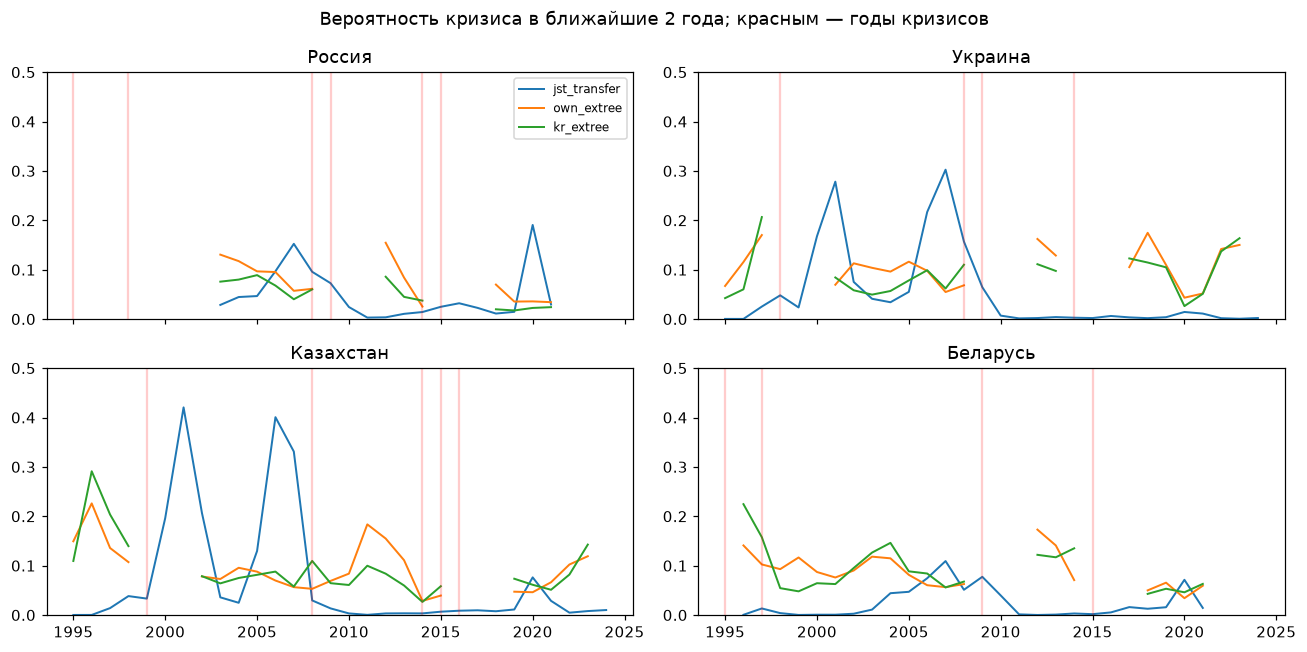

In [11]:
pred = pd.read_parquet(DATA_PROCESSED / "econ_predictions.parquet")
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, iso in zip(axes.flat, ["RUS", "UKR", "KAZ", "BLR"]):
    g = pred[(pred.iso3 == iso) & (pred.year >= 1995)]
    for m in ["jst_transfer", "own_extree", "kr_extree"]:
        ax.plot(g.year, g[m], label=m, lw=1.3)
    for y in g.loc[(g.deval25 == 1) | (g.gmd_crisis == 1), "year"]: ax.axvline(y, c="r", alpha=.2)
    ax.set_title(ISO3_TO_SHORT[iso]); ax.set_ylim(0, 0.5)
axes[0, 0].legend(fontsize=8); fig.suptitle("Вероятность кризиса в ближайшие 2 года; красным — годы кризисов"); plt.tight_layout(); plt.show()

## Итог

- Модель BoE повторена: на их данных совпали и таблица, и AUC (логрег 0,815 vs 0,816; деревья 0,863 vs 0,868).
- Перенос на постсоветские валютные кризисы не работает: AUC около 0,5. Модель BoE сделана под банковские кризисы после кредитных бумов в развитых странах, а постсоветские кризисы — валютные, с хронической инфляцией и внешними шоками.
- Подробнее — в отчёте `reports/2026-11-07-session-econ.md`.